# 02 - Experiments
Small, controlled experiments justifying the preprocessing and representation choices. All are scored on the **validation** split. The test split is reserved for `src/evaluation/evaluate.py`.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 140)
from src.utils import load_config
cfg = load_config()

In [2]:
from src.data.load_dataset import load_processed
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import f1_score
train, val = load_processed('train'), load_processed('val')
def score(Xtr, Xva, vec=None, clf=None):
    p = make_pipeline(vec or TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True), clf or LogisticRegression(C=5, max_iter=3000))
    p.fit(Xtr, train['category'])
    return round(f1_score(val['category'], p.predict(Xva), average='macro'), 4), len(p[0].vocabulary_)

## 1. Stemming vs lemmatisation

In [3]:
from nltk.stem import PorterStemmer
from src.preprocessing.text_preprocessor import TextPreprocessor
ps = PorterStemmer()
raw_pre = TextPreprocessor(lemmatize=False)
surface_tr = raw_pre.transform(train['text']); surface_va = raw_pre.transform(val['text'])
stem = lambda docs: [' '.join(ps.stem(w) for w in d.split()) for d in docs]
words = ['universities','studies','facilities','payments','paid','was','charged','attending','received']
pd.DataFrame({'word': words, 'porter stem': [ps.stem(w) for w in words],
              'spaCy lemma': [TextPreprocessor(remove_stopwords=False).transform([w])[0] for w in words]})

,word,porter stem,spaCy lemma
0,universities,univers,university
1,studies,studi,study
2,facilities,facil,facility
3,payments,payment,payment
4,paid,paid,pay
5,was,wa,be
6,charged,charg,charge
7,attending,attend,attend
8,received,receiv,receive


In [4]:
rows = []
for name, tr, va in [('no normalisation', surface_tr, surface_va), ('Porter stemming', stem(surface_tr), stem(surface_va)), ('spaCy lemmatisation', train['text_clean'], val['text_clean'])]:
    f1, v = score(tr, va); rows.append({'variant': name, 'val macro-F1': f1, 'vocabulary size': v})
pd.DataFrame(rows)

,variant,val macro-F1,vocabulary size
0,no normalisation,0.9895,6898
1,Porter stemming,0.9895,6600
2,spaCy lemmatisation,0.9884,6727


Both normalisations shrink the vocabulary. We keep **lemmatisation** because its features are real words (interpretable in the explainability table) while scoring on par with stemming.

## 2. Stop-word policy: keep negations vs remove all stop-words

In [5]:
keep = TextPreprocessor(); drop_all = TextPreprocessor(keep_words=())
rows = []
for name, pre in [('remove stop-words, KEEP negations (ours)', keep), ('remove ALL stop-words', drop_all), ('keep all words', TextPreprocessor(remove_stopwords=False))]:
    tr, va = pre.transform(train['text']), pre.transform(val['text'])
    f1, v = score(tr, va); rows.append({'policy': name, 'val macro-F1': f1, 'vocabulary': v})
pd.DataFrame(rows)

,policy,val macro-F1,vocabulary
0,"remove stop-words, KEEP negations (ours)",0.9884,6733
1,remove ALL stop-words,0.9884,6718
2,keep all words,0.9884,6852


In [6]:
print(keep.transform(['payment not received'])[0], '|', drop_all.transform(['payment not received'])[0], '|', drop_all.transform(['payment received'])[0])

payment not receive | payment receive | payment receive


Removing *not* makes "payment not received" identical to "payment received". On this dataset the F1 difference is small because category rarely depends on negation, but the policy matters for meaning (and for a future priority/sentiment model).

## 3. Representation: BoW vs TF-IDF, word vs word+char n-grams

In [7]:
from sklearn.pipeline import make_union
from sklearn.naive_bayes import MultinomialNB
X, V = train['text_clean'], val['text_clean']
rows = []
for name, vec in [('BoW unigram', CountVectorizer()), ('BoW 1-2gram', CountVectorizer(ngram_range=(1,2))), ('TF-IDF unigram', TfidfVectorizer(sublinear_tf=True)), ('TF-IDF 1-2gram', TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True)), ('TF-IDF word + char 2-5', make_union(TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True), TfidfVectorizer(analyzer='char_wb', ngram_range=(2,5), min_df=2, sublinear_tf=True)))]:
    for cname, clf in [('LR', LogisticRegression(C=5, max_iter=3000)), ('NB', MultinomialNB(alpha=0.1))]:
        p = make_pipeline(vec, clf).fit(X, train['category'])
        rows.append({'representation': name, 'classifier': cname, 'val macro-F1': round(f1_score(val['category'], p.predict(V), average='macro'), 4)})
pd.DataFrame(rows).pivot(index='representation', columns='classifier', values='val macro-F1')

classifier,LR,NB
representation,,
BoW 1-2gram,0.9829,0.9884
BoW unigram,0.9801,0.9819
TF-IDF 1-2gram,0.9884,0.9884
TF-IDF unigram,0.9856,0.9845
TF-IDF word + char 2-5,0.9895,0.9869


## 4. Robustness to typos: word vs char n-grams
We corrupt validation tickets with extra random typos and measure the drop.

In [8]:
import random
from src.data.generate_dataset import TicketGenerator
g = TicketGenerator(seed=0)
def corrupt(t):
    return ' '.join(g._typo(w) if random.random() < 0.25 else w for w in t.split())
random.seed(0)
noisy = TextPreprocessor().transform([corrupt(t) for t in val['text']])
rows = []
for name, vec in [('word TF-IDF', TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True)), ('word + char TF-IDF', make_union(TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True), TfidfVectorizer(analyzer='char_wb', ngram_range=(2,5), min_df=2, sublinear_tf=True)))]:
    p = make_pipeline(vec, LogisticRegression(C=5, max_iter=3000)).fit(X, train['category'])
    rows.append({'features': name, 'clean val F1': round(f1_score(val['category'], p.predict(V), average='macro'),4), 'typo-corrupted val F1': round(f1_score(val['category'], p.predict(noisy), average='macro'),4)})
pd.DataFrame(rows)

,features,clean val F1,typo-corrupted val F1
0,word TF-IDF,0.9884,0.9846
1,word + char TF-IDF,0.9895,0.9881


## 5. Final test-set comparison (from `reports/model_comparison.csv`)

In [9]:
cmp = pd.read_csv('reports/model_comparison.csv')
cmp[['display_name','accuracy','macro_f1','weighted_f1','val_macro_f1','latency_ms_per_ticket','train_time_sec','size_mb']]

,display_name,accuracy,macro_f1,weighted_f1,val_macro_f1,latency_ms_per_ticket,train_time_sec,size_mb
0,Naive Bayes (TF-IDF),0.9867,0.9865,0.9866,0.9870,1.543,61.25,0.82
1,Naive Bayes (BoW),0.9867,0.9865,0.9866,0.9884,1.713,0.29,0.76
2,DistilBERT (fine-tuned),0.9867,0.9863,0.9867,0.9868,0.849,53.60,268.80
3,Logistic Regression (TF-IDF),0.9853,0.9852,0.9853,0.9895,1.710,24.31,1.00
4,Linear SVM (TF-IDF),0.9853,0.9851,0.9853,0.9882,1.710,34.10,1.73
5,Logistic Regression (BoW),0.9840,0.9843,0.9840,0.9881,1.579,0.74,0.50
6,SBERT + Logistic Regression,0.9707,0.9699,0.9707,0.9813,0.760,72.27,91.59


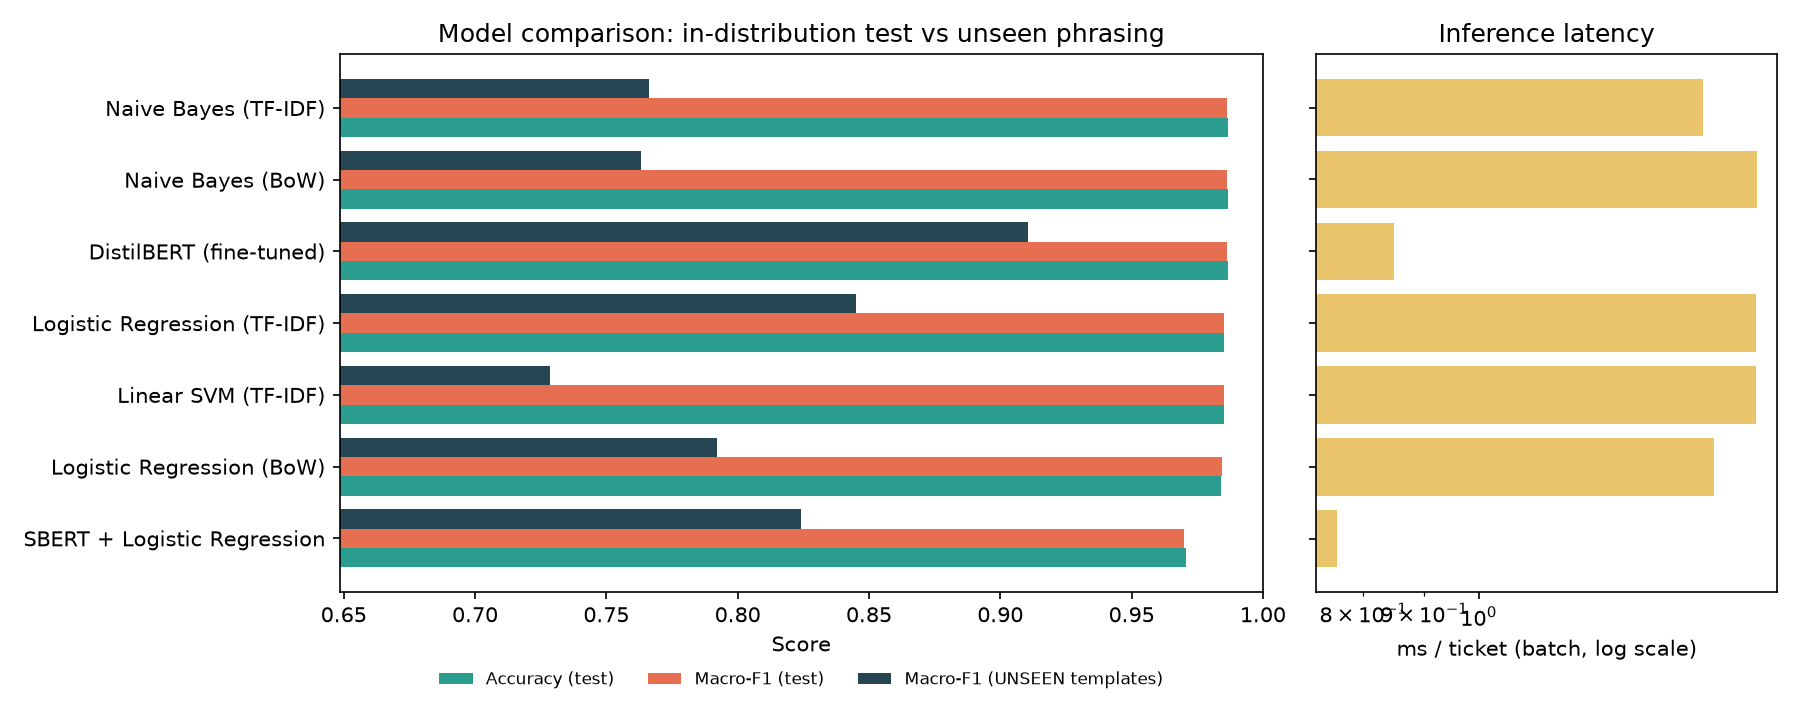

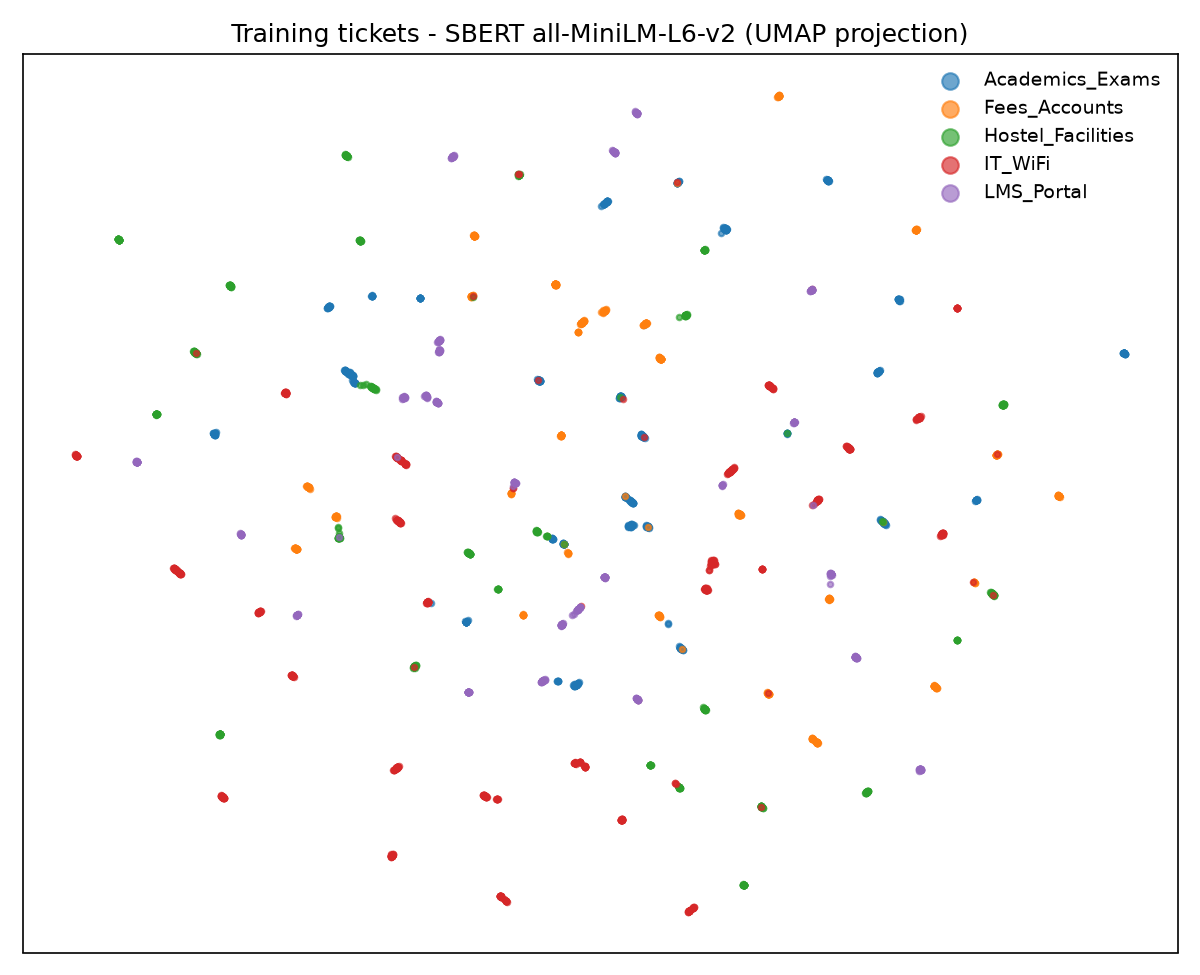

In [10]:
from IPython.display import Image, display
for f in ['model_comparison.png', 'embeddings_2d.png']:
    display(Image(filename=f'reports/figures/{f}', width=850))